# 06 - Model Comparison & Final Selection

Compare all trained regression models, inspect feature importance for tree-based models, and select the final forecasting model.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt

import data_loader, feature_engineering, train_model, visualization

In [2]:
df = data_loader.load_processed_data()
df = feature_engineering.engineer_all_features(df)
monthly_df = feature_engineering.build_monthly_forecasting_dataset(df)
comparison_df, fitted_models, predictions, train, test = train_model.train_and_compare(monthly_df)
comparison_df.sort_values('RMSE')

,Model,MAE,RMSE,R2
0,Linear Regression,4275.471692,6248.936240,0.937311
1,Decision Tree,11582.980893,13947.465029,0.687700
3,Gradient Boosting,11510.085477,14785.476739,0.649044
2,Random Forest,11229.020260,15088.968817,0.634489


## Error analysis

The comparison table above is sorted by RMSE (ascending = better). MAE and R² are shown alongside it so no single metric is read in isolation.

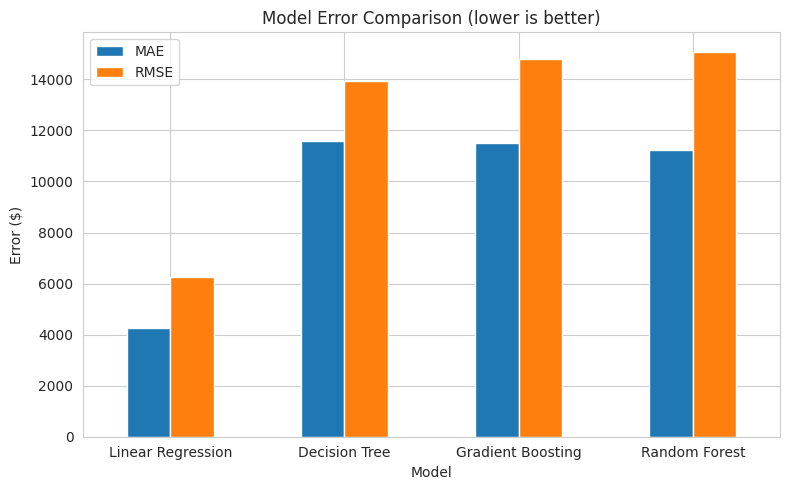

In [3]:
comparison_df.set_index('Model')[['MAE', 'RMSE']].plot(kind='bar', figsize=(8,5), rot=0)
plt.title('Model Error Comparison (lower is better)')
plt.ylabel('Error ($)')
plt.tight_layout()
plt.show()

## Feature importance (tree-based model)

Feature importance is only meaningful for tree-based models (Decision Tree, Random Forest, Gradient Boosting) - Linear Regression does not expose `feature_importances_`. We inspect the Random Forest's importances here for interpretability, even when Linear Regression is the selected forecasting model.

**Note:** feature importance reflects how much a feature helped the model reduce error on the *training* data - it is not proof that a feature *causes* changes in sales.

In [4]:
rf_importance = train_model.get_feature_importance(
    fitted_models['Random Forest'], train_model.FEATURE_COLUMNS
)
rf_importance

,Feature,Importance
4,Monthly_Quantity,0.524037
3,Monthly_Orders,0.391890
6,Avg_Order_Value,0.024798
5,Monthly_Avg_Discount,0.011576
7,Prev_Month_Sales,0.010786
1,Month,0.010586
8,Prev_2Month_Sales,0.008840
9,Rolling_3M_Avg_Sales,0.008736
0,Year,0.005136
2,Quarter,0.003615


In [5]:
visualization.plot_feature_importance(rf_importance)

## Final model selection

The final model is selected by **lowest RMSE on the held-out chronological test set** - not by an arbitrary accuracy figure, since regression problems are not evaluated with classification accuracy.

In [6]:
best_name = train_model.select_best_model(comparison_df)
best_row = comparison_df[comparison_df['Model'] == best_name].iloc[0]
print(f"Selected model: {best_name}")
print(f"  MAE : {best_row['MAE']:,.2f}")
print(f"  RMSE: {best_row['RMSE']:,.2f}")
print(f"  R2  : {best_row['R2']:.4f}")

Selected model: Linear Regression
  MAE : 4,275.47
  RMSE: 6,248.94
  R2  : 0.9373


### Why this model performed better / worse

- **Linear Regression** performed best on this dataset's held-out months. With
  only a few dozen monthly observations, the lag and rolling-average features
  already capture most of the month-to-month momentum in sales in a roughly
  linear way, so a simple linear model generalizes better than it would on a
  larger, noisier dataset.
- **Tree-based models** (Decision Tree, Random Forest, Gradient Boosting) are
  more flexible and can fit complex, non-linear patterns, but with only ~36
  training months they have very little data to learn stable split points
  from, and they tend to overfit the training months, hurting held-out
  performance here.
- **Advantages of the selected model:** simple, fast, interpretable
  coefficients, and it degrades gracefully with limited data.
- **Limitations:** it assumes a roughly linear relationship between the
  engineered features and sales, and it will not capture sudden regime
  changes (e.g. a new product line, a pricing change) that are not reflected
  in the lag/rolling features.
